# 在 Colab GPU 上运行 CQI × 前传压缩实验（Cat A / Cat B / option 8）

本笔记本在 Colab 运行时上克隆仓库、安装依赖，运行 `cqi_compression/run_cqi_bler.py` 的正式实验并汇总。实验设计、结果和注意事项见 [README.md](README.md) 与 [experiments.md](experiments.md)。

**这一版的变化**
- 新增 3GPP split option 8：O-DU 做到 IFFT + CP，前传传各天线的时域 IQ，按 CPRI 做均匀定点量化。Cat A 就是 Girycki 等论文中的 7-1（波束赋形在 DU），不再单列。
- 去掉了 GPU 自检和冒烟测试。冒烟测试已在本机 CPU 上跑通；正式运行中每个（撒点, 位宽）仍会用同一种子重跑一次 PDSCH，结果须逐位相同。
- 不挂载 Google Drive。结果写在运行时的本地磁盘 `/content/results/`，最后一个单元把原始数据打包成 base64 写进单元输出，随笔记本保存到本机。

**准备**
1. 运行时类型选 GPU（A100 / L4 均可）。
2. 运行时从 GitHub 克隆 `main`，看不到本机文件：本机对代码的修改要先推送。

**在 VS Code 中使用**：用 Colab 扩展把内核连接到 Colab 运行时后，从上到下逐个运行。运行时断开后 `/content` 下的文件全部丢失，所以第 5 单元运行期间保持连接，跑完立刻运行第 6、7 单元并保存笔记本。

**在本机取回结果**（保存笔记本之后）：
```bash
python cqi_compression/extract_colab_results.py cqi_compression/colab_continue.ipynb results/cqi_compression_20261030/colab_main
python cqi_compression/analyse_cqi_bler.py results/cqi_compression_20261030/colab_main
```
取回后再清空笔记本输出并提交。

In [1]:
# 1. 设置
REPO = "Agata872/Sionna-based-Simulation"
BRANCH = "main"
WORKDIR = "/content/Sionna-based-Simulation"
RESULTS = "/content/results/cqi_compression_20261030"   # 运行时本地磁盘，不用 Google Drive
RUN = "main"           # 运行目录名；目录中已有 rows.jsonl 时脚本拒绝覆盖，重跑请换名字（如 main2）
DEVICE = "cuda:0"
RT_LLVM = False        # 射线追踪报 OptiX 错误时改为 True（射线追踪改用 CPU，链路仍在 GPU）
DROPS = 50
CATEGORIES = "A B 8"   # 7.2x Cat A、Cat B，split option 8

In [2]:
# 2. 克隆或更新仓库（公开仓库，不需要令牌）
import os
import subprocess

if not os.path.isdir(WORKDIR):
    subprocess.run(["git", "clone", "--depth", "1", "--branch", BRANCH, f"https://github.com/{REPO}.git", WORKDIR],
                   check=True)
else:
    subprocess.run(["git", "-C", WORKDIR, "pull", "--ff-only"], check=True)
os.chdir(WORKDIR)
os.makedirs(RESULTS, exist_ok=True)
!git log --oneline -3

f0cc68d (grafted, HEAD -> main, origin/main, origin/HEAD) Enhance O-RAN simulation to support 3GPP split option 8


In [3]:
# 3. 安装依赖：沿用 Colab 自带的 torch（Sionna 2.2.0 要求 torch >= 2.9.1），只装 Sionna 和中文字体
!pip install -q sionna==2.2.0 sionna-rt==2.2.0
!apt-get -qq install -y fonts-noto-cjk > /dev/null && rm -rf ~/.cache/matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.61.2 requires numpy<2.3,>=1.24, but you have numpy 2.5.4 which is incompatible.
tensorflow 2.21.0 requires h5py<3.15.0,>=3.11.0, but you have h5py 3.16.0 which is incompatible.


In [4]:
# 4. 环境检查：GPU、torch、Mitsuba 变体（cuda_ad_* 表示射线追踪在 GPU 上）
!nvidia-smi --query-gpu=name,driver_version,memory.total --format=csv
!python -c "import torch, sionna.phy, mitsuba as mi, sionna.rt; print('torch', torch.__version__, '| CUDA', torch.version.cuda, '| GPU 可用', torch.cuda.is_available(), '| Mitsuba', mi.variant())"

name, driver_version, memory.total [MiB]
Tesla T4, 580.82.07, 15360 MiB
torch 2.11.0+cu130 | CUDA 13.0 | GPU 可用 True | Mitsuba cuda_ad_mono_polarized


In [5]:
# 5. 正式运行：50 个撒点 ×（Cat A、Cat B 各 8 个位宽 + option 8 的 10 个位宽）× 4 个周期。
#    A100 上预计约 25 分钟（运行 Q5 只有 Cat A/B，用了 14.5 分钟）。结果只在运行时本地磁盘上，运行期间保持连接。
OUT = f"{RESULTS}/{RUN}"
RT = "--rt-llvm" if RT_LLVM else ""
!python cqi_compression/run_cqi_bler.py --device {DEVICE} {RT} --drops {DROPS} --categories {CATEGORIES} --out {OUT} 2>&1 \
    | grep -v "Warning\|LDPC5GEncoder" | tee {OUT}.log

Cat A：初始化 15.0 s（链路 cuda:0，射线追踪 cuda_ad_mono_polarized）
Cat A 撒点   0 | SNR  26.2  28.8 dB | CQI(精灵) [15, 14] | BLER genie/csi-rs/aware/oracle：ideal: 0.00/0.00/0.00/0.00 | 9: 0.00/0.00/0.00/0.00 | 8: 0.00/0.00/0.00/0.00 | 7: 0.00/0.00/0.00/0.00 | 6: 0.00/0.00/0.00/0.00 | 5: 1.00/1.00/0.50/0.00 | 4: 1.00/1.00/1.00/0.00 | 3: 1.00/1.00/0.88/0.32 | 51.3 s
Cat A 撒点   1 | SNR  43.3  10.9 dB | CQI(精灵) [15, 10] | BLER genie/csi-rs/aware/oracle：ideal: 0.00/0.00/0.00/0.00 | 9: 0.00/0.00/0.00/0.00 | 8: 0.00/0.00/0.00/0.00 | 7: 0.00/0.00/0.00/0.00 | 6: 0.00/0.00/0.00/0.00 | 5: 0.00/0.00/0.00/0.00 | 4: 0.50/0.50/0.50/0.50 | 3: 1.00/0.50/0.50/0.50 | 24.3 s
Cat A 撒点   2 | SNR  36.7  47.5 dB | CQI(精灵) [15, 15] | BLER genie/csi-rs/aware/oracle：ideal: 0.00/0.00/0.00/0.00 | 9: 0.00/0.00/0.00/0.00 | 8: 0.00/0.00/0.00/0.00 | 7: 0.46/0.46/0.00/0.00 | 6: 0.50/0.38/0.00/0.00 | 5: 0.50/0.50/0.00/0.00 | 4: 1.00/1.00/0.62/0.61 | 3: 1.00/1.00/0.59/0.68 | 34.8 s
Cat A 撒点   3 | SNR  23.7  40.1 dB | CQI(精灵) [13, 15] 

排除理想前传下精灵 CQI 也失败的 UE-撒点 33/300 个（链路本身不可用，与压缩无关）
7.2x 块缩放 U-plane（Cat B 权值 same），option 8 时域 fixed，2 UE × 2 层，MCS / CQI 表 2，51 PRB，OLLA 关闭（CQI 查表），50 个撒点 × 4 个周期 × 7 个数据时隙

实际 U-plane 信号上的 SQNR [dB]（第一个撒点；option 8 为 PRB 上的 SQNR，时域为全带宽 SQNR）：
  Cat A           9 bit    8 bit    7 bit    6 bit    5 bit    4 bit    3 bit
  bfp              49.3     43.2     37.2     31.2     25.2     19.1     13.1
  block_scaling    52.2     46.1     40.0     33.7     27.4     21.2     15.0
  mu_law           49.3     43.2     37.1     31.1     25.0     18.8     12.2
  Cat B           9 bit    8 bit    7 bit    6 bit    5 bit    4 bit    3 bit
  bfp              50.9     43.7     43.7     29.0     27.4     21.1     14.5
  block_scaling    55.7     49.7     41.7     34.1     28.5     21.7     15.4
  mu_law           45.1     43.7     35.8     30.3     23.8     23.6     15.4
  option 8       16 bit   12 bit    9 bit    8 bit    7 bit    6 bit    5 bit    4 bit    3 bit
  fixed            87.9     65.3     4

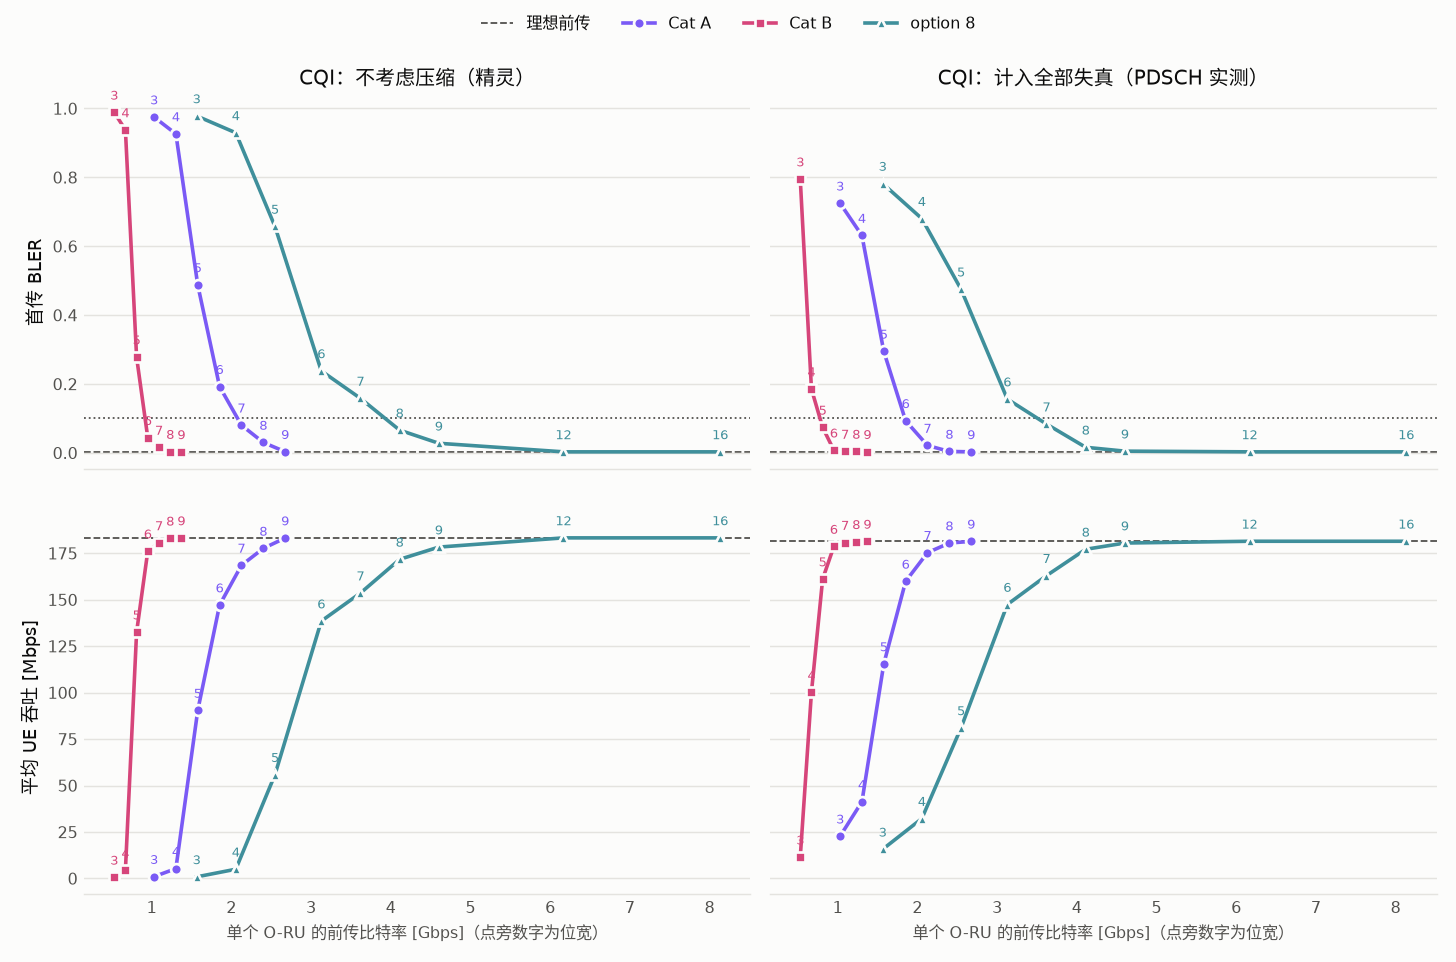

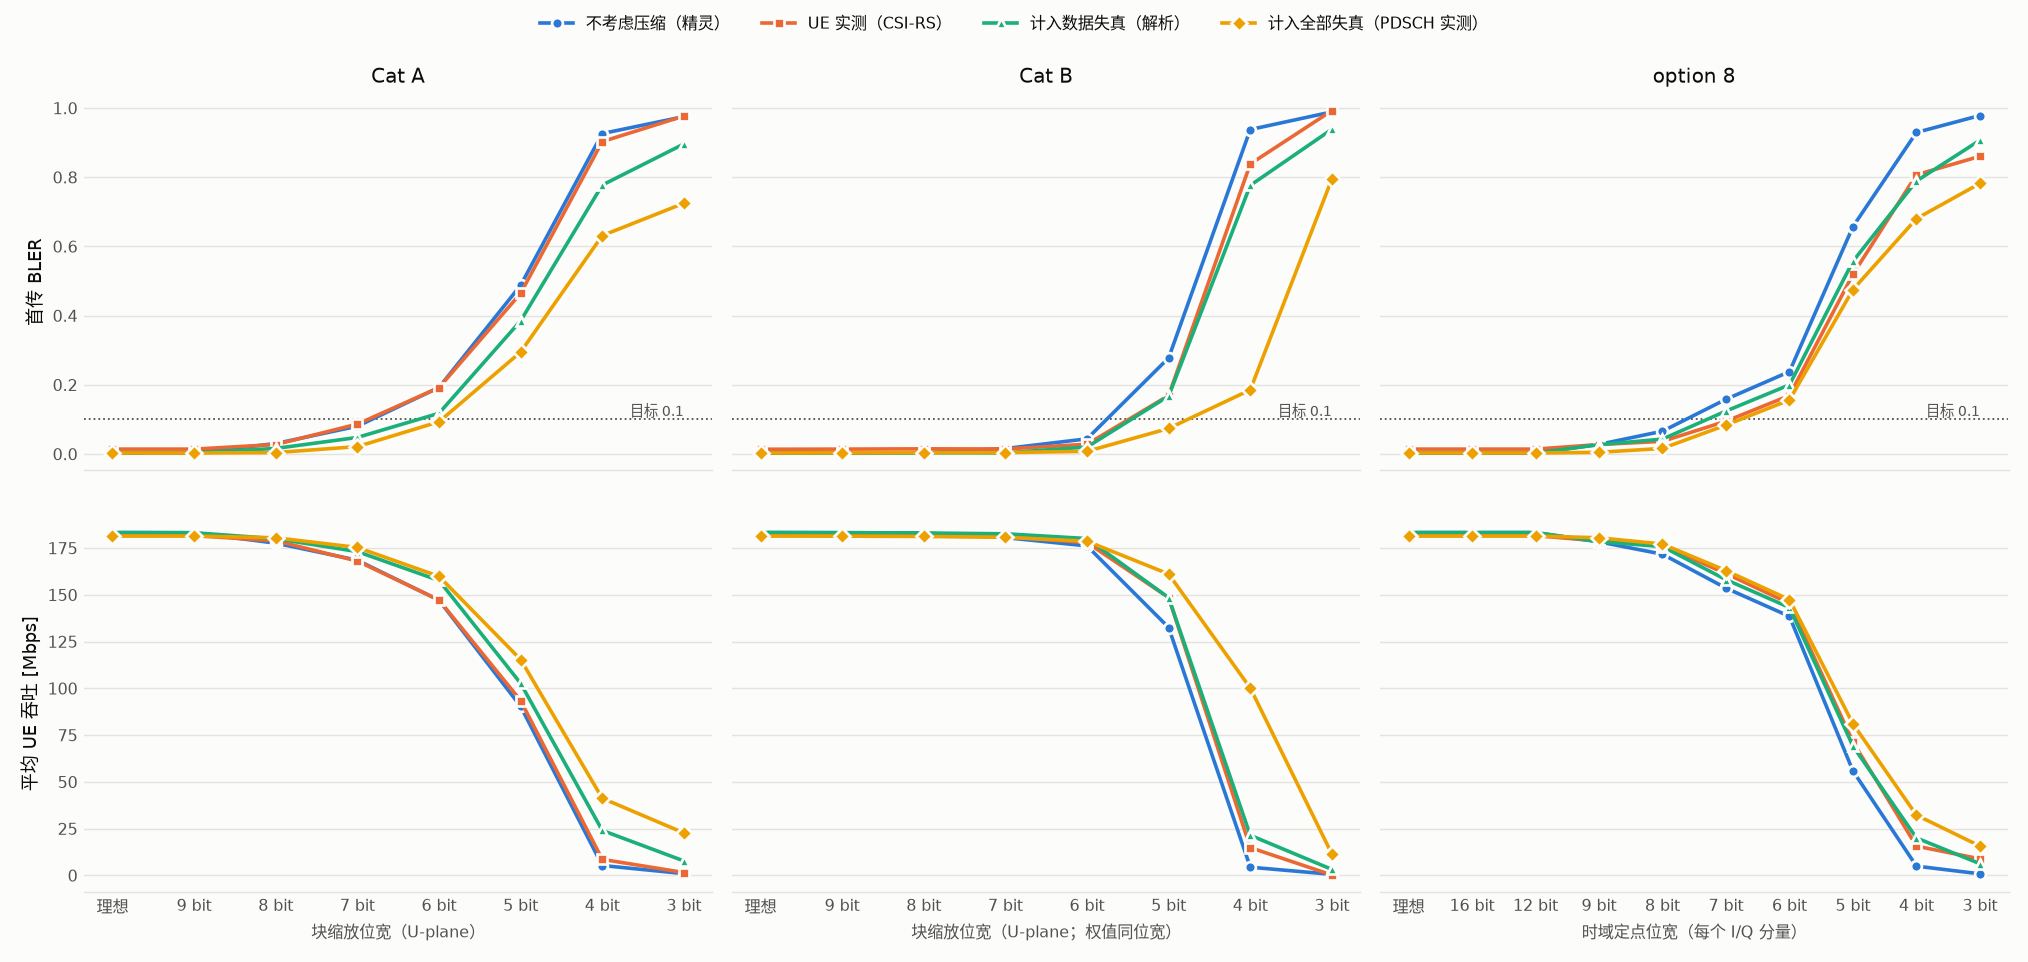

In [6]:
# 6. 汇总：表格与两张图（图也随笔记本保存到本机）。报告开头出现"复核不一致"警告时，本次结果作废
!python cqi_compression/analyse_cqi_bler.py {OUT}
from IPython.display import Image, display
for name in ("fig_split_vs_fronthaul.png", "fig_bler_tput_vs_width.png"):
    display(Image(f"{OUT}/{name}"))

In [7]:
# 7. 把原始数据（rows.jsonl、metadata.json、codec_sqnr.json、complete.json、日志等，不含图）打包成 zip，
#    以 base64 写进本单元的输出。保存笔记本后，在本机用 extract_colab_results.py 解压（见开头说明）。
import base64
import hashlib
import io
import zipfile
from pathlib import Path

buf = io.BytesIO()
with zipfile.ZipFile(buf, "w", zipfile.ZIP_DEFLATED, compresslevel=9) as z:
    for p in sorted(Path(OUT).iterdir()):
        if p.suffix != ".png":
            z.write(p, p.name)
    z.write(f"{OUT}.log", "main.log")
data = buf.getvalue()
print(f"结果包 {len(data) / 1e6:.2f} MB")
print("-----BEGIN RESULTS ZIP-----")
print("sha256", hashlib.sha256(data).hexdigest())
print(base64.encodebytes(data).decode(), end="")
print("-----END RESULTS ZIP-----")

结果包 0.57 MB
-----BEGIN RESULTS ZIP-----
sha256 ...
-----END RESULTS ZIP-----
